# 5A. Bayesian inference: detecting a faint signal

**Mathematical Methods for Physicists II | Compiled undergraduate coursework**

Can a Gaussian-shaped pulse be distinguished from noise when its location is unknown? We simulate measurements, estimate pulse parameters under the signal model, then compare that model with noise alone.

Start with the coin example to learn the Bayesian update, then apply it to a pulse in noise. All data here are simulated; the true values are used only to generate the data and check the result.

In [11]:
from scipy.stats import beta
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit, logsumexp

rng = np.random.default_rng(51)

def midpoint_grid(lower, upper, count):
    # Each grid point represents one equal-width cell inside the prior bounds.
    edges = np.linspace(lower, upper, count + 1)
    
    return (edges[:-1] + edges[1:]) / 2, edges

def central_interval(mass, edges):
    # Interpolate the cumulative mass at cell edges (uniform within each cell).
    cdf = np.r_[0, np.cumsum(mass)]
    cdf[-1] = 1.0
    
    return np.interp([0.025, 0.975], cdf, edges)


## 1. What does Bayesian updating mean?

Bayes' rule says

$$p(\theta\mid D)=\frac{p(D\mid\theta)p(\theta)}{p(D)},$$

where $\theta$ is an unknown parameter, $p(\theta)$ is the **prior**, $p(D\mid\theta)$ is the **likelihood**, and $p(\theta\mid D)$ is the **posterior** after seeing data $D$.

Warm-up: suppose a coin has unknown probability $p$ of landing heads. Here $p$ plays the role of $\theta$ in Bayes’ rule. Beta is the name of a family of distributions over values between 0 and 1. We use it to describe which values of $p$ are plausible; its two numbers, $a$ and $b$, control the shape of the curve. Start with a $\rm Beta(2,2) $ prior and observe 8 heads in 12 flips. The posterior is $\rm Beta(2+8,2+4)=\rm Beta(10,6)$. Both curves are distributions of possible values of $p$, not distributions of the number of heads.

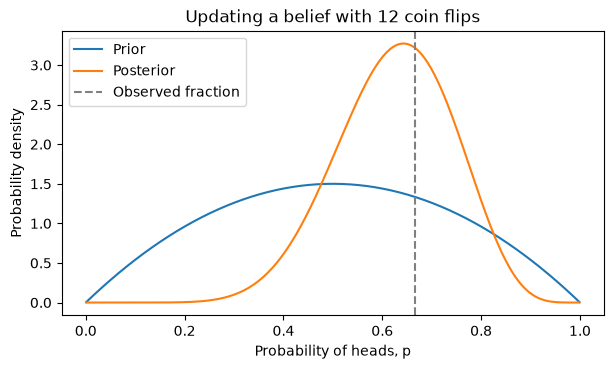

Posterior mean: 0.625
Central 95% credible interval: [0.384 0.837]


In [12]:
# A head increases the first Beta shape; a tail increases the second.
heads = 8
flips = 12
prior_a, prior_b = 2, 2
post_a = prior_a + heads
post_b = prior_b + flips - heads
p_values = np.linspace(0.001, 0.999, 300)

plt.figure(figsize=(7, 3.7))
plt.plot(p_values, beta.pdf(p_values, prior_a, prior_b), label='Prior')
plt.plot(p_values, beta.pdf(p_values, post_a, post_b), label='Posterior')
plt.axvline(heads/flips, color='gray', linestyle='--', label='Observed fraction')
plt.xlabel('Probability of heads, p')
plt.ylabel('Probability density')
plt.title('Updating a belief with 12 coin flips')
plt.legend()
plt.show()

print('Posterior mean:', round(post_a/(post_a+post_b), 3))
print('Central 95% credible interval:', np.round(beta.ppf([0.025, 0.975], post_a, post_b), 3))


**Takeaway:** Eight heads shift the prior toward larger values of $p$. The posterior mean lies between the prior mean and the observed fraction; the curve gives uncertainty about $p$.

## 2. Repeat the update numerically

A $\mathrm{Beta}(a,b)$ prior has density proportional to $p^{a-1}(1-p)^{b-1}$. Multiply by the binomial likelihood, proportional to $p^h(1-p)^{n-h}$, and the powers give the analytic $\mathrm{Beta}(a+h,b+n-h)$ posterior. The binomial coefficient is fixed by the observed counts and cancels from this parameter update.

A grid reproduces the same calculation without needing an analytic posterior. Evaluate the prior and likelihood at cell centres, turn their product into cell masses, then divide by the total. Here the cells have equal width, so that common factor cancels.

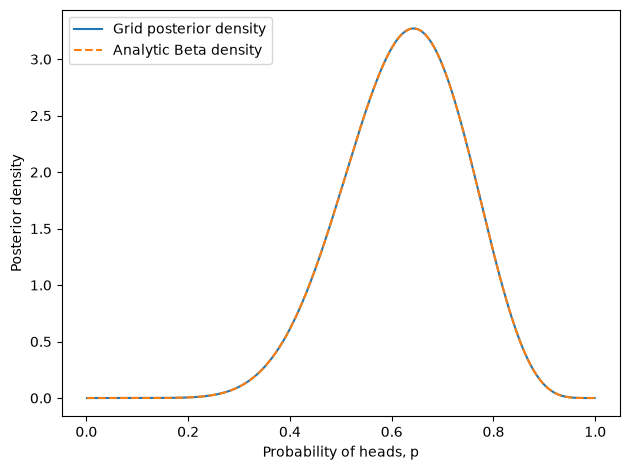

Grid mean: 0.6250000000000105
Grid central 95% credible interval: [0.38379577 0.83664451]
Predictive probability of heads on the next flip: 0.6250000000000105


In [13]:
p_grid, p_edges = midpoint_grid(0, 1, 400)

# Add log prior and log likelihood: both depend on the candidate p.
log_weight = beta.logpdf(p_grid, prior_a, prior_b)
log_weight += heads*np.log(p_grid) + (flips-heads)*np.log1p(-p_grid)
mass = np.exp(log_weight - log_weight.max())
mass /= mass.sum()
dp = p_edges[1] - p_edges[0]

plt.plot(p_grid, mass/dp, label='Grid posterior density')
plt.plot(p_grid, beta.pdf(p_grid, post_a, post_b), '--', label='Analytic Beta density')
plt.xlabel('Probability of heads, p')
plt.ylabel('Posterior density')
plt.legend()
plt.tight_layout()
plt.show()

print('Grid mean:', np.dot(p_grid, mass))
print('Grid central 95% credible interval:', central_interval(mass, p_edges))

# Average the next-flip probability over uncertain p.
print('Predictive probability of heads on the next flip:', np.dot(p_grid, mass))


**Takeaway:** The grid and analytic densities overlap. In this model the probability of heads on the next flip is the posterior average of $p$, about 0.625.

Next we use the same grid idea to estimate the amplitude and location of a faint pulse.

## 3. Hide a Gaussian pulse in noise

Measure a signal at positions $x_i$. If a pulse exists, its mean shape is

$$g(x;A,c)=A\exp\left[-\frac{(x-c)^2}{2w^2}\right],$$

where $A\geq0$ is amplitude, $c$ is the centre, and $w$ is the **known** width. Assume independent Gaussian measurement errors $\epsilon_i\sim\mathcal N(0,\sigma^2)$ with known $\sigma$ and zero baseline:

$$y_i=g(x_i;A,c)+\epsilon_i.$$

**Task:** generate one dataset. The true parameters are shown for teaching, but the inference cells below will only use the measurements and the stated known quantities.


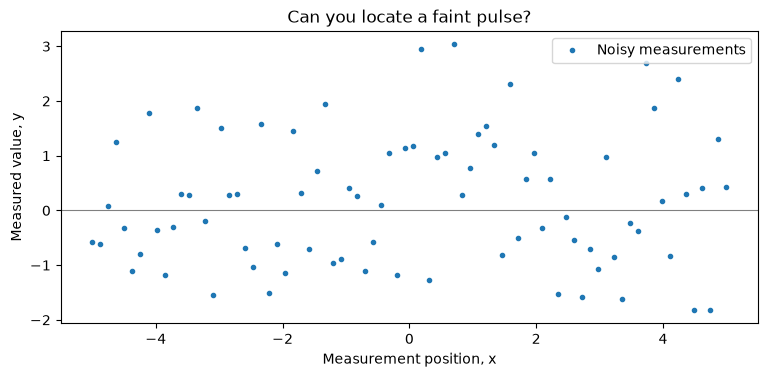

In [14]:
def pulse(x, amplitude, center, width):
    # A unit-amplitude pulse peaks at one; scaling changes its height, not its width.
    return amplitude*np.exp(-0.5*((x-center)/width)**2)

x = np.linspace(-5, 5, 80)
known_width = 0.50
known_noise = 1.0
true_amplitude = 1.5
true_center = 0.7
measurement = pulse(x, true_amplitude, true_center, known_width)

# Draw an independent noise value at each position.
measurement = measurement + rng.normal(0, known_noise, size=len(x))

plt.figure(figsize=(9, 3.8))
plt.plot(x, measurement, 'o', markersize=3, label='Noisy measurements')
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlabel('Measurement position, x')
plt.ylabel('Measured value, y')
plt.title('Can you locate a faint pulse?')
plt.legend()
plt.show()


**Takeaway:** The pulse is hard to spot in individual measurements. The search combines evidence from nearby measurements using the expected pulse shape.

## 4. Likelihood and priors for a signal

Under the **no-signal hypothesis** $H_0$, $A=0$ and $y_i$ are Gaussian noise. Under the **signal hypothesis** $H_1$, both $A$ and $c$ are unknown. For each candidate pair $(A,c)$, the Gaussian log-likelihood differs from that of $H_0$ by

$$\log\frac{p(D\mid A,c,H_1)}{p(D\mid H_0)}
=\frac{A}{\sigma^2}\sum_i y_i q_i(c)
-\frac{A^2}{2\sigma^2}\sum_i q_i(c)^2,$$

where $q_i(c)=\exp[-(x_i-c)^2/(2w^2)]$.

Choose explicit, simple priors under $H_1$: $A$ uniform on $[0,4]$ and $c$ uniform on $[-2,2]$. Evaluate the likelihood on a grid. These prior ranges are **part of the model**, not measurements from the data.


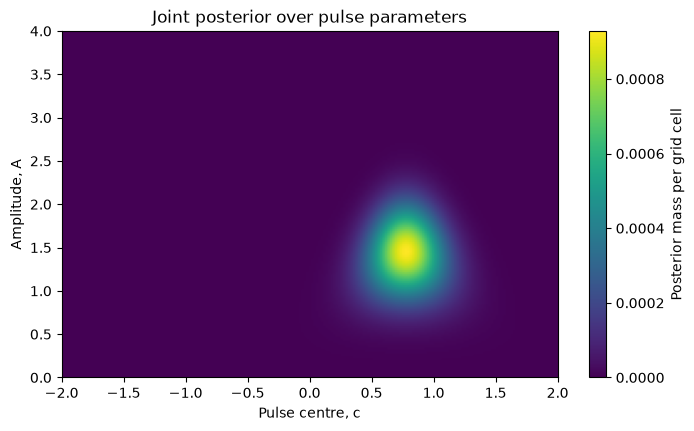

In [15]:
amplitudes, amplitude_edges = midpoint_grid(0, 4, 161)
centers, center_edges = midpoint_grid(-2, 2, 201)
templates = np.array([pulse(x, 1, c, known_width) for c in centers])

# Each row of templates is the pulse shape for one possible centre.
# Dot products measure how strongly the data line up with each pulse shape.
projection = templates @ measurement
size_squared = np.sum(templates**2, axis=1)

# Broadcasting evaluates all amplitude-centre pairs: rows are A, columns are c.
log_ratio = (amplitudes[:, None]*projection[None, :]/known_noise**2
             - 0.5*amplitudes[:, None]**2*size_squared[None, :]/known_noise**2)

# The prior is uniform, so posterior mass on the grid is proportional to likelihood.
# Shift the largest log weight to zero before exponentiating.
relative_weight = np.exp(log_ratio - np.max(log_ratio))
posterior = relative_weight/np.sum(relative_weight)

plt.figure(figsize=(8, 4.5))
plt.imshow(posterior, origin='lower', aspect='auto',
           extent=[center_edges[0], center_edges[-1], amplitude_edges[0], amplitude_edges[-1]])
plt.colorbar(label='Posterior mass per grid cell')
plt.xlabel('Pulse centre, c')
plt.ylabel('Amplitude, A')
plt.title('Joint posterior over pulse parameters')
plt.show()


**Takeaway:** Bright cells show which amplitude and centre pairs carry the most posterior mass, assuming a pulse exists. Summing over one axis gives the uncertainty in the other parameter.

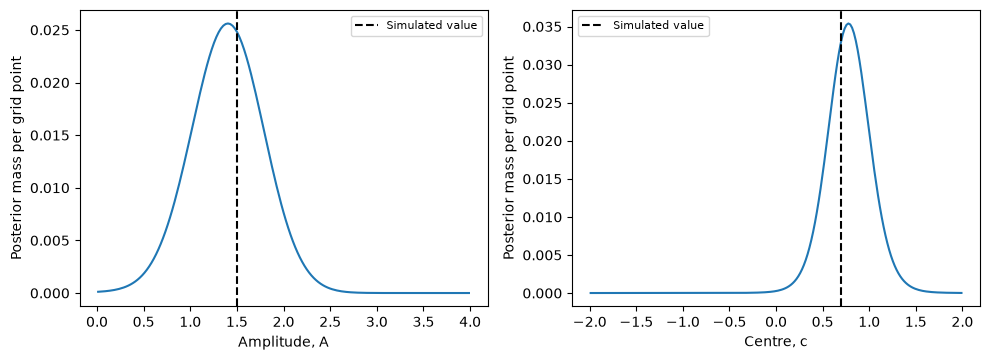

Amplitude posterior mean: 1.397 | central 95% interval: [0.624 2.153]
Centre posterior mean: 0.78 | central 95% interval: [0.312 1.257]


In [16]:
# Summing over one axis averages out the corresponding unknown parameter.
posterior_A = np.sum(posterior, axis=1)
posterior_c = np.sum(posterior, axis=0)
mean_A = np.sum(amplitudes*posterior_A)
mean_c = np.sum(centers*posterior_c)
interval_A = central_interval(posterior_A, amplitude_edges)
interval_c = central_interval(posterior_c, center_edges)

plt.figure(figsize=(10, 3.7))
plt.subplot(1, 2, 1)
plt.plot(amplitudes, posterior_A)
plt.axvline(true_amplitude, color='black', linestyle='--', label='Simulated value')
plt.xlabel('Amplitude, A')
plt.ylabel('Posterior mass per grid point')
plt.legend(fontsize=8)
plt.subplot(1, 2, 2)
plt.plot(centers, posterior_c)
plt.axvline(true_center, color='black', linestyle='--', label='Simulated value')
plt.xlabel('Centre, c')
plt.ylabel('Posterior mass per grid point')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Amplitude posterior mean:', round(mean_A, 3), '| central 95% interval:', np.round(interval_A, 3))
print('Centre posterior mean:', round(mean_c, 3), '| central 95% interval:', np.round(interval_c, 3))


**Takeaway:** The two curves show uncertainty in amplitude and centre separately, conditional on a pulse. Dashed lines mark the simulated truth and are not used by the fit.

**Task:** compare the fitted shape with the measurements. Use the posterior means as a simple representative curve; it is not required to pass through every noisy point. Here $w$ and $\sigma$ are held fixed, so the displayed parameter uncertainty does not include uncertainty in those assumptions.


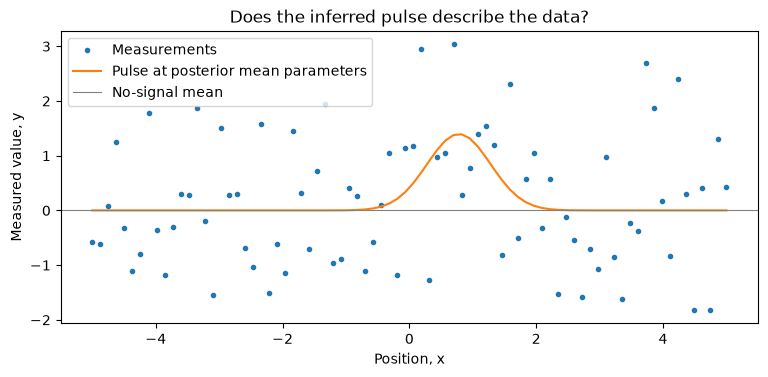

In [17]:
plt.figure(figsize=(9, 3.8))
plt.plot(x, measurement, 'o', markersize=3, label='Measurements')
plt.plot(x, pulse(x, mean_A, mean_c, known_width), label='Pulse at posterior mean parameters')
plt.axhline(0, color='gray', linewidth=0.8, label='No-signal mean')
plt.xlabel('Position, x')
plt.ylabel('Measured value, y')
plt.title('Does the inferred pulse describe the data?')
plt.legend()
plt.show()


**Takeaway:** The curve shows one representative pulse. Scatter around it is expected, and the overlay alone does not establish that a pulse exists.

## 5. Is there evidence for a signal at all?

A narrow posterior for $A$ and $c$ **assuming $H_1$** does not by itself compare $H_1$ with $H_0$. For that comparison, average the likelihood across the full prior range under $H_1$:

$$B_{10}=\frac{p(D\mid H_1)}{p(D\mid H_0)}
=\frac{1}{(A_{\max}-A_{\min})(c_{\max}-c_{\min})}
\int\!\int\frac{p(D\mid A,c,H_1)}{p(D\mid H_0)}\,dA\,dc.$$

$B_{10}$ is a **Bayes factor**. Because our grid is evenly spaced, its average likelihood ratio approximates this integral. Use a stable log-sum-exp calculation to take that average. With prior odds of 1:1, posterior odds equal $B_{10}:1$; without prior odds, $B_{10}$ is not itself a probability that a signal exists.


In [18]:
# A uniform prior over equal-area cells gives the mean likelihood ratio.
log_bayes_factor = logsumexp(log_ratio) - np.log(log_ratio.size)
bayes_factor = np.exp(log_bayes_factor)

# With equal prior odds, log posterior odds equal log B10.
posterior_probability_signal = expit(log_bayes_factor)

print('Bayes factor B10:', round(bayes_factor, 3))
print('Posterior P(signal | data) with 1:1 prior odds:', round(posterior_probability_signal, 3))


Bayes factor B10: 55.442
Posterior P(signal | data) with 1:1 prior odds: 0.982


## 6. A frequentist noise-only check

For comparison, search the possible centres for the strongest positive pulse-like pattern and repeat that **entire search** on 400 simulated noise-only datasets. The fraction producing a peak at least as large as ours estimates a $p$-value under $H_0$. It is **not** the posterior probability that $H_0$ is true. Repeating the full search matters because the centre was not known in advance.


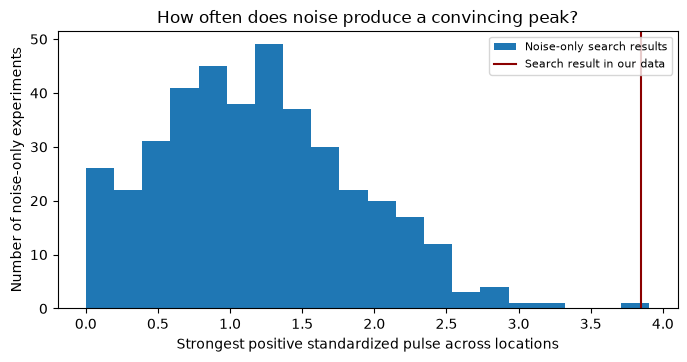

Noise-only p-value (400 trials): 0.005
Smallest resolvable p-value in this run: 0.0025


In [19]:
# Divide each template projection by its noise SD, then keep the largest positive match.
observed_strength = np.max(np.maximum(projection/(known_noise*np.sqrt(size_squared)), 0))
noise_only_data = rng.normal(0, known_noise, size=(400, len(x)))
noise_projections = noise_only_data @ templates.T
null_strength = np.max(np.maximum(noise_projections/(known_noise*np.sqrt(size_squared)), 0), axis=1)

# Include the observed search in the Monte Carlo rank; the estimate cannot be zero.
p_value = (1+np.sum(null_strength>=observed_strength))/(len(null_strength)+1)

plt.figure(figsize=(8, 3.6))
plt.hist(null_strength, bins=20, label='Noise-only search results')
plt.axvline(observed_strength, color='darkred', label='Search result in our data')
plt.xlabel('Strongest positive standardized pulse across locations')
plt.ylabel('Number of noise-only experiments')
plt.title('How often does noise produce a convincing peak?')
plt.legend(fontsize=8)
plt.show()
print('Noise-only p-value (400 trials):', round(p_value, 4))
print('Smallest resolvable p-value in this run:', round(1/(len(null_strength)+1), 4))


**Takeaway:** The histogram shows the strongest match from each noise-only search. Compare the vertical line with that distribution to see how unusual the observed match is after scanning all centres.

## 7. Does the amplitude prior matter?

The Bayes factor averages over the whole prior parameter space. If we allow a much wider amplitude and centre range, many additional pulse shapes will fit poorly; the result can change even though the dataset has not changed. Repeat the calculation with $A\in[0,8]$ and $c\in[-4,4]$ to see this dependence. This is one reason priors for model comparison should be stated clearly.


In [20]:
# Double the bin counts along each axis to keep the original grid spacing.
wide_amplitudes, _ = midpoint_grid(0, 8, 322)
wide_centers, _ = midpoint_grid(-4, 4, 402)
wide_templates = np.array([pulse(x, 1, c, known_width) for c in wide_centers])
wide_projection = wide_templates @ measurement
wide_size = np.sum(wide_templates**2, axis=1)
wide_log_ratio = (wide_amplitudes[:, None]*wide_projection[None, :]/known_noise**2
                  - 0.5*wide_amplitudes[:, None]**2*wide_size[None, :]/known_noise**2)
wide_bayes_factor = np.exp(logsumexp(wide_log_ratio) - np.log(wide_log_ratio.size))
print('B10 with A in [0,4], c in [-2,2]:', round(bayes_factor, 3))
print('B10 with A in [0,8], c in [-4,4]:', round(wide_bayes_factor, 3))


B10 with A in [0,4], c in [-2,2]: 55.442
B10 with A in [0,8], c in [-4,4]: 13.893


**Takeaway:** Widening both priors changes the Bayes factor without changing the data. This comparison tests the two bounds together; vary one at a time to isolate its effect.

## What to take away

- The posterior answers **which amplitudes and positions are plausible if a pulse is present**.
- The Bayes factor compares the complete signal model with a no-signal model; its value depends on their assumptions and parameter priors.
- The noise-only $p$-value asks how often a search like ours would produce at least this strong a peak **if there were no pulse**. It answers a different question from the Bayes factor.
- The width, noise level, independent-error assumption, and zero baseline were treated as known. Real applications often need to estimate or check these too.
